In [1]:
#!/usr/bin/env python
# -*- coding: utf-8 -*-

"""
Modularized pipeline for detecting nuclear recoil tracks in rock CT slices.
The code is structured in blocks:
  1. Configuration & Hyperparameters
  2. Imports
  3. Preprocessing Functions
  4. Artificial Line Injection Functions
  5. Edge Detection Function
  6. Visualization Functions
  7. Resize and Bounding Box Adjustment Functions
  8. Model Architecture (BBoxRegressor)
  9. Custom Dataset (LineDetectionDataset)
 10. Single Image Processing Pipeline (for debugging/visualization)
 11. Training Loop
 12. Evaluation & Visualization of Predictions
 13. Main Execution Block
"""

# -----------------------------------------------------------------------------
# BLOCK 1: Configuration & Hyperparameters
# -----------------------------------------------------------------------------
config = {
    "PREPROCESSING": {
        "sigma": 1,
        "clip_limit": 0.01,
    },
    "ARTIFICIAL_INJECTION": {
        "num_lines": 5,
        "thickness": 3,
        "intensity_scale": 0.01,
    },
    "MODEL": {
        "input_channels": 1,  # Grayscale images
        "img_size": 128,
        "conv1": {"out_channels": 32, "kernel_size": 10, "stride": 5},
        "conv2": {"out_channels": 64, "kernel_size": 3},
        "conv3": {"out_channels": 128, "kernel_size": 3},
        "pool_kernel": 2,
        "pool_stride": 2,
        "fc1_out": 128,
        "fc2_out": 64,
        "bbox_out": 4,  # (x_center, y_center, width, height)
    },
    "TRAINING": {
        "learning_rate": 1e-4,
        "num_epochs": 50,
        "batch_size": 128,
        "scheduler_gamma": 0.9,
        "num_workers": 2,
        "pin_memory": True,
    },
    "DATA": {
        "input_folder": "",      # For single image processing (adjust as needed)
        "data_dir": "/content",  # Directory for dataset images
        "img_shape": 128,
    }
}




In [2]:
# -----------------------------------------------------------------------------
# BLOCK 2: Imports
# -----------------------------------------------------------------------------
import os
import numpy as np
import tifffile
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from skimage.exposure import rescale_intensity, equalize_adapthist
import cv2

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import Normalize
from torch import optim
from torch.optim.lr_scheduler import ExponentialLR
from tqdm import tqdm
import matplotlib.patches as patches


In [3]:

# -----------------------------------------------------------------------------
# BLOCK 3: Preprocessing Functions
# -----------------------------------------------------------------------------
def preprocess_image(image, sigma=config["PREPROCESSING"]["sigma"], clip_limit=config["PREPROCESSING"]["clip_limit"]):
    """
    Preprocess a single image: denoise, normalize, and enhance contrast.
    """
    # Denoising using a Gaussian filter.
    denoised_image = gaussian_filter(image, sigma=sigma)
    # Normalize intensities to [0, 1].
    normalized_image = rescale_intensity(denoised_image, in_range='image', out_range=(0, 1))
    # Enhance contrast using adaptive histogram equalization.
    enhanced_image = equalize_adapthist(normalized_image, clip_limit=clip_limit)
    return enhanced_image


In [4]:

# -----------------------------------------------------------------------------
# BLOCK 4: Artificial Line Injection Functions
# -----------------------------------------------------------------------------
def inject_artificial_lines(image,
                            num_lines=config["ARTIFICIAL_INJECTION"]["num_lines"],
                            thickness=config["ARTIFICIAL_INJECTION"]["thickness"],
                            intensity_scale=config["ARTIFICIAL_INJECTION"]["intensity_scale"],
                            return_lines=False):
    """
    Inject artificial lines into an image to simulate subtle tracks.
    """
    height, width = image.shape
    line_image = np.copy(image)
    lines = []

    for _ in range(num_lines):
        # Choose random start and end points.
        x1, y1 = np.random.randint(0, width), np.random.randint(0, height)
        x2, y2 = np.random.randint(0, width), np.random.randint(0, height)
        lines.append([x1, y1, x2, y2])

        # Set the line intensity to be slightly different from the mean.
        mean_intensity = np.mean(image)
        line_intensity = mean_intensity + intensity_scale * mean_intensity

        # Draw the line on the image.
        cv2.line(line_image, (x1, y1), (x2, y2), color=(line_intensity), thickness=thickness)

    if return_lines:
        return line_image, np.array(lines)
    else:
        return line_image


In [5]:
# -----------------------------------------------------------------------------
# BLOCK 4.2: Artificial Dot Injection Functions
# -----------------------------------------------------------------------------
def inject_artificial_points(image, num_points=5, radius=10, intensity_scale=config["ARTIFICIAL_INJECTION"]["intensity_scale"], return_points=False):
    height, width = image.shape
    point_image = np.copy(image)
    points = []

    for _ in range(num_points):
        x, y = np.random.randint(0, width), np.random.randint(0, height)
        points.append([x, y])

        mean_intensity = np.mean(image)
        point_intensity = mean_intensity + intensity_scale * mean_intensity

        # image = cv2.circle(image, (x,y), radius=0, color=(0, 0, 255), thickness=-1)
        # image = cv2.circle(image, (x,y), radius=radius, color=(point_intensity), thickness=-1)
        image = cv2.circle(point_image, (x,y), radius=radius, color=(0, 0, 0), thickness=-1)

    if return_points:
        return point_image, np.array(points)
    else:
        return point_image

In [6]:

# -----------------------------------------------------------------------------
# BLOCK 5: Edge Detection Function -- not called in the script
# -----------------------------------------------------------------------------
def detect_edges(image):
    """
    Detect edges in the image using the Canny Edge Detector.
    """
    # Convert image from [0,1] to [0,255] and to uint8.
    uint8_image = (image * 255).astype(np.uint8)
    edges = cv2.Canny(uint8_image, threshold1=50, threshold2=150)
    return edges



In [7]:
# -----------------------------------------------------------------------------
# BLOCK 6: Visualization Functions
# -----------------------------------------------------------------------------
def display_pipeline(original, original_with_lines, preprocessed, edges):
    """
    Display the various stages of the processing pipeline.
    """
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))

    axes[0].imshow(original, cmap='gray')
    axes[0].set_title("Original Image")
    axes[0].axis('off')

    axes[1].imshow(original_with_lines, cmap='gray')
    axes[1].set_title("Original + Artificial Lines")
    axes[1].axis('off')

    axes[2].imshow(preprocessed, cmap='gray')
    axes[2].set_title("Preprocessed Image")
    axes[2].axis('off')

    axes[3].imshow(edges, cmap='gray')
    axes[3].set_title("Detected Edges")
    axes[3].axis('off')

    plt.tight_layout()
    plt.show()


def show_image_with_bbox(image, bbox, bbox_format='corners', color='red', linewidth=2):
    """
    Display an image with a bounding box overlay.
    """
    fig, ax = plt.subplots(1)
    ax.imshow(image, cmap='gray')

    if bbox_format == 'center':
        x_center, y_center, width, height = bbox
        x_min = x_center - width / 2
        y_min = y_center - height / 2
    elif bbox_format == 'corners':
        x_min, y_min, x_max, y_max = bbox
        width = x_max - x_min
        height = y_max - y_min
    else:
        raise ValueError("bbox_format must be either 'center' or 'corners'")

    rect = patches.Rectangle((x_min, y_min), width, height,
                             linewidth=linewidth, edgecolor=color, facecolor='none')
    ax.add_patch(rect)
    plt.axis('off')
    plt.show()



In [8]:
# -----------------------------------------------------------------------------
# BLOCK 7: Resize and Bounding Box Adjustment Functions
# -----------------------------------------------------------------------------
def resize_image_and_bbox_cv(image, bbox, new_size, bbox_format='center'):
    """
    Resize an image and adjust the bounding box accordingly.
    """
    orig_height, orig_width = image.shape[:2]
    new_width, new_height = new_size
    scale_x = new_width / orig_width
    scale_y = new_height / orig_height

    # Resize the image.
    resized_image = cv2.resize(image, new_size)

    # Update bounding box coordinates.
    if bbox_format == 'center':
        x_center, y_center, width, height = bbox
        new_bbox = (
            x_center * scale_x,
            y_center * scale_y,
            width * scale_x,
            height * scale_y
        )
    elif bbox_format == 'corners':
        x_min, y_min, x_max, y_max = bbox
        new_bbox = (
            x_min * scale_x,
            y_min * scale_y,
            x_max * scale_x,
            y_max * scale_y
        )
    else:
        raise ValueError("bbox_format must be either 'center' or 'corners'")

    return resized_image, new_bbox


In [ ]:

# -----------------------------------------------------------------------------
# BLOCK 8: Model Architecture - Bounding Box Regressor
# -----------------------------------------------------------------------------
class BBoxRegressor(nn.Module):
    def __init__(self, input_channels=config["MODEL"]["input_channels"], img_size=config["DATA"]["img_shape"]):
        super(BBoxRegressor, self).__init__()
        # Convolutional layers for feature extraction.
        self.conv1 = nn.Conv2d(input_channels,
                               config["MODEL"]["conv1"]["out_channels"],
                               kernel_size=config["MODEL"]["conv1"]["kernel_size"],
                               stride=config["MODEL"]["conv1"]["stride"])
        self.conv2 = nn.Conv2d(config["MODEL"]["conv1"]["out_channels"],
                               config["MODEL"]["conv2"]["out_channels"],
                               kernel_size=config["MODEL"]["conv2"]["kernel_size"])
        self.conv3 = nn.Conv2d(config["MODEL"]["conv2"]["out_channels"],
                               config["MODEL"]["conv3"]["out_channels"],
                               kernel_size=config["MODEL"]["conv3"]["kernel_size"])

        self.pool = nn.MaxPool2d(kernel_size=config["MODEL"]["pool_kernel"],
                                 stride=config["MODEL"]["pool_stride"])

        # Dynamically compute the flattened feature dimension.
        dummy_input = torch.zeros(1, input_channels, img_size, img_size)
        x = self.pool(F.relu(self.conv1(dummy_input)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))
        fc_input_dim = x.view(1, -1).size(1)

        self.fc1 = nn.Linear(fc_input_dim, config["MODEL"]["fc1_out"])
        self.fc2 = nn.Linear(config["MODEL"]["fc1_out"], config["MODEL"]["fc2_out"])
        self.fc3 = nn.Linear(config["MODEL"]["fc2_out"], config["MODEL"]["bbox_out"])

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))
        x = x.view(x.size(0), -1)  # Flatten
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x



In [ ]:
# -----------------------------------------------------------------------------
# BLOCK 9: Custom Dataset for Line Detection
# -----------------------------------------------------------------------------
class LineDetectionDataset(Dataset):
    def __init__(self, processed_data_dir=config["DATA"]["data_dir"],
                 thickness=config["ARTIFICIAL_INJECTION"]["thickness"],
                 intensity_scale=config["ARTIFICIAL_INJECTION"]["intensity_scale"],
                 img_shape=config["DATA"]["img_shape"]):
        super().__init__()

        self.images = []
        self.bboxes = []
        self.normalize = Normalize(mean=[0.5], std=[0.5])

        # Iterate over TIFF files in the directory.
        for file in os.listdir(processed_data_dir):
            if file.endswith("tiff"):
                # Read the image in grayscale.
                image = cv2.imread(os.path.join(processed_data_dir, file), cv2.IMREAD_GRAYSCALE)
                image = image.astype(np.float32) / 255.0  # Normalize to [0,1]

                # Inject one artificial line and get its bounding box.
                image, line = inject_artificial_lines(image, num_lines=1,
                                                      thickness=thickness,
                                                      intensity_scale=intensity_scale,
                                                      return_lines=True)
                # Resize the image and adjust the bounding box.
                image, line = resize_image_and_bbox_cv(image, line[0], (img_shape, img_shape), bbox_format='corners')

                # Convert to tensor and normalize.
                image_tensor = self.normalize(torch.from_numpy(image).unsqueeze(0).float())
                # Normalize bounding box coordinates to [0,1].
                line_tensor = torch.tensor(line).float() / (img_shape - 1)

                self.images.append(image_tensor)
                self.bboxes.append(line_tensor)

    def get_img_shape(self):
        return self.images[0].shape[1:]

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        return self.images[idx], self.bboxes[idx]



In [8]:
def detect_points(image):
    thresh = cv2.threshold(image, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)[1]

    thresh = thresh.astype('uint8')

    # Filter out large non-connecting objects
    cnts = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cnts = cnts[0] if len(cnts) == 2 else cnts[1]
    for c in cnts:
        area = cv2.contourArea(c)
        if area > 5:
            cv2.drawContours(thresh,[c],0,0,-1)

    # kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3,3))
    # opening = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=3)

    cnts = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cnts = cnts[0] if len(cnts) == 2 else cnts[1]

    for c in cnts:
        ((x, y), r) = cv2.minEnclosingCircle(c)
        print(x, y, r)
        # cv2.circle(image, (int(x), int(y)), int(r), (36, 255, 12), 2)

    return thresh

    # cv2_imshow(thresh)
    # cv2_imshow(image)


In [9]:
# -----------------------------------------------------------------------------
# BLOCK 10: Single Image Processing Pipeline (For Debugging/Visualization)
# -----------------------------------------------------------------------------
def process_and_visualize_single_image():
    input_folder = config["DATA"]["input_folder"]
    image_path = os.path.join(input_folder, "0049.tiff")  # Example image path

    # Load the original image.
    original_image = tifffile.imread(image_path)

    # Inject artificial lines.
    # original_with_lines = inject_artificial_lines(
    #     original_image,
    #     num_lines=2,
    #     thickness=config["ARTIFICIAL_INJECTION"]["thickness"],
    #     intensity_scale=config["ARTIFICIAL_INJECTION"]["intensity_scale"]
    # )
    original_with_lines = inject_artificial_points(
        original_image,
        radius=1,
        num_points=5,
    )

    thresh = detect_points(original_with_lines)

    plt.figure(figsize=(10, 8))
    plt.imshow(thresh, cmap="gray")
    # plt.title("Original Image")
    plt.axis('off')

    plt.show()

    # detect_points(original_with_lines)

    # Preprocess the image.
    # preprocessed_image = preprocess_image(original_with_lines)
    # # Detect edges.
    # edges_detected = detect_edges(preprocessed_image)

    # # Display all pipeline steps.
    # display_pipeline(original_image, original_with_lines, preprocessed_image, edges_detected)



586.0 839.0 1.000100016593933
179.0 753.0 1.000100016593933
429.0 302.0 1.000100016593933
429.0 151.0 1.000100016593933


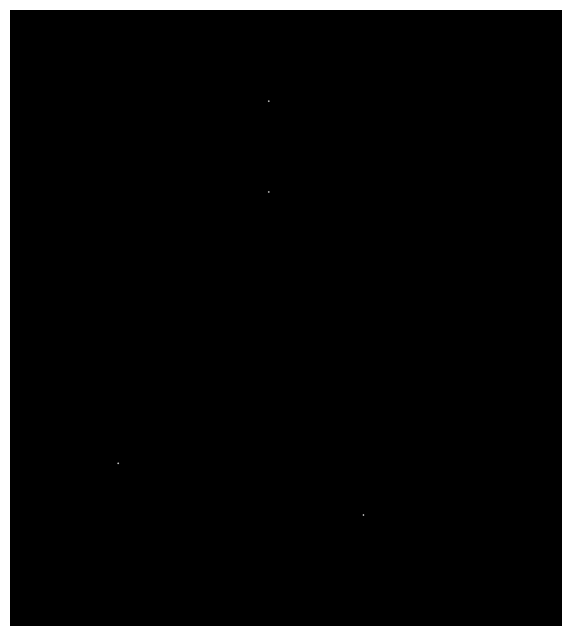

In [17]:
process_and_visualize_single_image()

In [ ]:
# -----------------------------------------------------------------------------
# BLOCK 11: Training Loop
# -----------------------------------------------------------------------------
def train_model():
    device = 'cuda' if torch.cuda.is_available() else 'cpu'
    print(f'Using device: {device}')

    data_dir = config["DATA"]["data_dir"]
    img_shape = config["DATA"]["img_shape"]

    dataset = LineDetectionDataset(processed_data_dir=data_dir,
                                   img_shape=img_shape,
                                   thickness=config["ARTIFICIAL_INJECTION"]["thickness"],
                                   intensity_scale=config["ARTIFICIAL_INJECTION"]["intensity_scale"])
    dataloader = DataLoader(dataset,
                            batch_size=config["TRAINING"]["batch_size"],
                            shuffle=True,
                            num_workers=config["TRAINING"]["num_workers"],
                            pin_memory=config["TRAINING"]["pin_memory"])

    sample_img_shape = dataset.get_img_shape()
    print("Image shape from dataset:", sample_img_shape)

    model = BBoxRegressor(input_channels=config["MODEL"]["input_channels"],
                          img_size=img_shape).to(device)
    #criterion = nn.MSELoss()
    criterion = nn.SmoothL1Loss()

    optimizer = optim.Adam(model.parameters(), lr=config["TRAINING"]["learning_rate"])
    scheduler = ExponentialLR(optimizer, gamma=config["TRAINING"]["scheduler_gamma"])

    num_epochs = config["TRAINING"]["num_epochs"]

    for epoch in range(num_epochs):
        running_loss = 0.0
        for imgs, bboxes in tqdm(dataloader, desc=f"Epoch {epoch+1}/{num_epochs}"):
            imgs, bboxes = imgs.float().to(device), bboxes.float().to(device)

            optimizer.zero_grad()  # Clear gradients
            pred_bboxes = model(imgs)
            loss = criterion(pred_bboxes, bboxes)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        scheduler.step()
        epoch_loss = running_loss / len(dataset)
        print(f"Epoch {epoch + 1}/{num_epochs}, Loss: {epoch_loss:.4f}")

    return model, dataset


In [ ]:

# -----------------------------------------------------------------------------
# BLOCK 12: Evaluation & Visualization of Predictions
# -----------------------------------------------------------------------------
def evaluate_model(model, dataset):
    # Take the first sample for evaluation.
    test_img, test_bbox = dataset[7]
    device = next(model.parameters()).device

    pred_bbox = model(test_img.unsqueeze(0).float().to(device))
    pred_bbox = pred_bbox.cpu().detach().numpy()[0]

    # Denormalize bounding boxes for display.
    img_shape = config["DATA"]["img_shape"]
    true_bbox_display = test_bbox.numpy() * (img_shape - 1)
    pred_bbox_display = pred_bbox * (img_shape - 1)

    # Display ground truth bounding box.
    show_image_with_bbox(test_img[0].numpy(), true_bbox_display, bbox_format='corners')
    # Display predicted bounding box.
    show_image_with_bbox(test_img[0].numpy(), pred_bbox_display, bbox_format='corners')



Using device: cuda
Image shape from dataset: torch.Size([128, 128])


Epoch 1/50: 100%|██████████| 7/7 [00:00<00:00, 30.32it/s]


Epoch 1/50, Loss: 0.0015


Epoch 2/50: 100%|██████████| 7/7 [00:00<00:00, 31.07it/s]


Epoch 2/50, Loss: 0.0015


Epoch 3/50: 100%|██████████| 7/7 [00:00<00:00, 31.89it/s]


... (91 outputs left out)

Epoch 49/50: 100%|██████████| 7/7 [00:00<00:00, 31.45it/s]


Epoch 49/50, Loss: 0.0004


Epoch 50/50: 100%|██████████| 7/7 [00:00<00:00, 30.03it/s]


Epoch 50/50, Loss: 0.0004


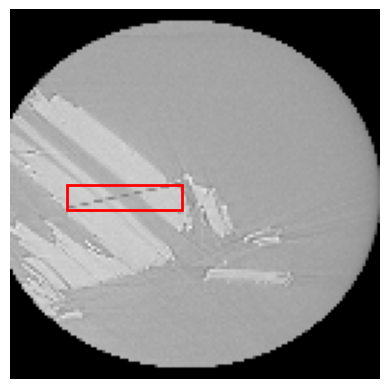

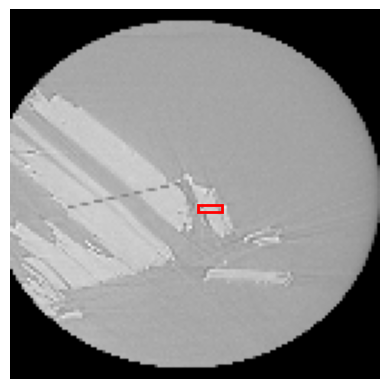

In [ ]:
# -----------------------------------------------------------------------------
# BLOCK 13: Main Execution Block
# -----------------------------------------------------------------------------
if __name__ == "__main__":
    # Uncomment the following line to run the single image processing pipeline for debugging.
    # process_and_visualize_single_image()

    # Train the model.
    model, dataset = train_model()

    # Evaluate the trained model.
    evaluate_model(model, dataset)